# 1 · Static methods (the baseline)

Before training anything, measure the extrapolators that need **no model**: show the
newest frame again, continue the change in brightness, or continue the motion.

The task is **2x frame generation**: the stream sends every second frame, and from the two it
received last - frames N-2 and N - the client makes frame N+1, the one the host never sent,
before N+2 arrives. Every method below gets those two frames and is scored on N+1.

They set the bar on two sides:

- **quality** - a learned model has to score higher than the best of them *on the samples
  where something changed*. Over every sample, repeating the newest frame is close to
  perfect on a desktop, and every method looks good;
- **speed** - a guess is only worth drawing if it is ready before the frame it stands in
  for would have been, so it has the frame time (33 ms at 30 fps) minus decoding and drawing.

At the end, the three ONNX can express as plain arithmetic are exported for the client.

Needs: `00_data_preprocess.ipynb`. Results: `summary.md`, "Static methods".

In [1]:
"""Settings and data."""

import matplotlib.pyplot as plt
import numpy as np
import torch

from helpers import metrics, models, runs, speed, training, webexport
from helpers.training import DATA_DIR, DEVICE

CONTEXT, AHEAD = 2, 1     # the client's contract: two received frames in, the frame after the newest out
BENCH_SIZES = [(640, 360), (960, 540), (1280, 720), (1920, 1080)]   # stream frames
SEED = 0

manifest = training.load_manifest()
training.describe(manifest)
HALO = manifest["halo"]
STEP = runs.received_every(manifest)   # display frames between two received ones: 2
FRACTION = AHEAD / STEP                # the share of their motion to carry to the frame made: ½

# every validation run at its fixed sample: (previous, current), and the frame after
inputs, targets = runs.load(DATA_DIR, "val", manifest, CONTEXT, AHEAD)
masks = runs.groups(manifest, "val", inputs[:, -1], targets, HALO)
KINDS = [kind for kind in ("page", "desktop", "photo", "video", "cursor") if kind in masks]
for kind in KINDS:
    masks[f"{kind}, changed"] = masks[kind] & masks["changed"]
print("val    ", inputs.shape, "->", targets.shape)
print("samples", {name: int(mask.sum()) for name, mask in masks.items() if "," not in name})

device  cuda NVIDIA GeForce RTX 3090
stream  x2 down from a 1280x720 window, 60 fps
run     96 px (64 px + a halo of 16), 8 frames each
stream  every 2th frame received - the inputs are frames N-2 and N, the target N+1 (2x frame generation)
val     (1677, 2, 96, 96, 3) -> (1677, 96, 96, 3)
samples {'all': 1677, 'changed': 749, 'unchanged': 928, 'cursor': 164, 'page': 686, 'desktop': 431, 'video': 160, 'photo': 400}


## The methods

- **repeat** shows the newest frame again: a 30 fps stream shown at 60 with every frame twice,
  and what every other method has to beat;
- **linear** continues each pixel's change in brightness, `current + (current - previous)`:
  the mock graph the client runs now. Fed two received frames, it lands on N+2, a whole
  received interval ahead of the frame it has to make. It is right for a fade and wrong
  wherever something moves - a moved edge is drawn twice, once too dark and once too light;
- **half step** goes half as far, `current + (current - previous) / 2`: the same idea aimed
  at N+1, the frame in between;
- **shift** continues the *motion* instead: it finds the whole-pixel offset that carries
  `previous` onto `current` best (luma L1, searching every offset within the radius) and
  moves `current` by `FRACTION` of it - half, from N to N+1. For the **tile** there is one offset for the whole
  picture - right for a scroll or a pan and for nothing else; with **blocks**, each 16 or 8
  pixel block finds its own, which can follow a cursor or a dragged window but also finds
  false matches in repeating text.

The shift methods search as far as the halo: content that moved further came from outside
the tile, and no method that sees only the tile can know what it was.

In [2]:
"""The methods, and their quality on every validation sample, by group."""

METHODS = {
    "repeat": models.Repeat(),
    "linear": models.Blend(1.0),
    "half step": models.Blend(0.5),
    "shift, tile": models.Shift(radius=HALO, block=None, fraction=FRACTION),
    "shift, 16 px blocks": models.Shift(radius=HALO, block=16, fraction=FRACTION),
    "shift, 8 px blocks": models.Shift(radius=HALO, block=8, fraction=FRACTION),
}

results = {name: training.evaluate(method.to(DEVICE), inputs, targets, masks, trim=HALO)
           for name, method in METHODS.items()}

for group in ("changed", "all", "unchanged"):
    print(f"\n{group}: {masks[group].sum()} samples")
    metrics.print_table({name: scores[group] for name, scores in results.items()},
                        extra=lambda name, s, g=group: f"   {s['wpsnr'] - results['repeat'][g]['wpsnr']:+6.2f} dB vs repeat")


changed: 749 samples
                         wpsnr   psnr-y   psnr-u   psnr-v  psnr-rgb   ssim-y
repeat                   25.69    24.50    62.00    62.61     24.31   0.7040    +0.00 dB vs repeat
linear                   21.94    20.75    58.29    58.72     20.60   0.6326    -3.75 dB vs repeat
half step                23.94    22.74    60.46    60.80     22.59   0.6692    -1.76 dB vs repeat
shift, tile              35.80    34.84    65.77    66.28     34.13   0.8675   +10.11 dB vs repeat
shift, 16 px blocks      34.37    33.37    65.47    65.99     32.74   0.8634    +8.68 dB vs repeat
shift, 8 px blocks       33.02    32.01    65.25    65.72     31.40   0.8569    +7.33 dB vs repeat

all: 1677 samples
                         wpsnr   psnr-y   psnr-u   psnr-v  psnr-rgb   ssim-y
repeat                   58.38    57.66    79.27    79.62     56.80   0.8673    +0.00 dB vs repeat
linear                   52.44    51.66    74.41    74.74     50.84   0.8313    -5.94 dB vs repeat
half step    

In [3]:
"""By kind of source, on the samples where something changed."""

for key, label, digits in (("ssim", "SSIM-Y", 4), ("wpsnr", "wPSNR (dB)", 2)):
    print(f"{label + ', changed':<22}" + "".join(f"{kind:>10}" for kind in KINDS))
    for name, scores in results.items():
        print(f"{name:<22}" + "".join(f"{scores[f'{kind}, changed'][key]:10.{digits}f}" for kind in KINDS))
    print(f"{'samples':<22}" + "".join(f"{masks[f'{kind}, changed'].sum():10}" for kind in KINDS) + "\n")

SSIM-Y, changed             page   desktop     photo     video    cursor
repeat                    0.6723    0.7668    0.6462    0.9277    0.7170
linear                    0.6185    0.7154    0.5355    0.8823    0.6537
half step                 0.6413    0.7313    0.5981    0.9132    0.6829
shift, tile               0.8108    0.7912    0.9249    0.9643    0.8257
shift, 16 px blocks       0.8103    0.7745    0.9148    0.9688    0.8083
shift, 8 px blocks        0.8008    0.7705    0.9112    0.9646    0.8012
samples                      350        52       248        99        43

wPSNR (dB), changed         page   desktop     photo     video    cursor
repeat                     23.49     25.94     25.04     34.98     26.15
linear                     19.77     23.06     21.00     31.40     22.25
half step                  21.44     24.48     23.37     33.89     24.15
shift, tile                35.68     27.55     36.89     37.84     31.64
shift, 16 px blocks        33.97     27.20     35.

## The halo

The client cuts a frame into tiles with a halo of 4 pixels. A tile that is to continue a
motion has to see where its content is coming from, and anything that moved more than 4
pixels in a frame came from outside it. The set stores a halo of 16, so the cost can be
measured before anyone changes the client: the shift methods at a radius (and halo) of 4, 8
and 16, scored on the same 64 px cores.

And how far things move: the offset the tile method finds between the two inputs, over
the scrolled and panned samples (pages and photos) that changed. An offset at the edge of
the search, 16, means "at least that far".

In [4]:
"""The shift methods at the client's halo and wider."""

HALOS = [4, 8, 16]
by_halo = {}
for halo in HALOS:
    x, y = runs.load(DATA_DIR, "val", manifest, CONTEXT, AHEAD, halo=halo)
    for block in (None, 16):
        scores = training.evaluate(models.Shift(radius=halo, block=block, fraction=FRACTION), x, y,
                                   {"changed": masks["changed"]}, trim=halo)
        by_halo[halo, block] = scores["changed"]

print(f"{'changed samples':<22}" + "".join(f"{f'halo {h}':>18}" for h in HALOS))
print(f"{'':<22}" + "".join(f"{'SSIM-Y':>9}{'wPSNR':>9}" for _ in HALOS))
for block in (None, 16):
    name = "shift, tile" if block is None else f"shift, {block} px blocks"
    print(f"{name:<22}" + "".join(f"{by_halo[h, block]['ssim']:9.4f}{by_halo[h, block]['wpsnr']:9.2f}" for h in HALOS))
repeat = results["repeat"]["changed"]
print(f"{'repeat':<22}" + f"{repeat['ssim']:9.4f}{repeat['wpsnr']:9.2f}" * len(HALOS))

changed samples                   halo 4            halo 8           halo 16
                         SSIM-Y    wPSNR   SSIM-Y    wPSNR   SSIM-Y    wPSNR
shift, tile              0.8261    34.82   0.8657    35.96   0.8675    35.80
shift, 16 px blocks      0.8165    32.77   0.8561    34.15   0.8634    34.37
repeat                   0.7040    25.69   0.7040    25.69   0.7040    25.69


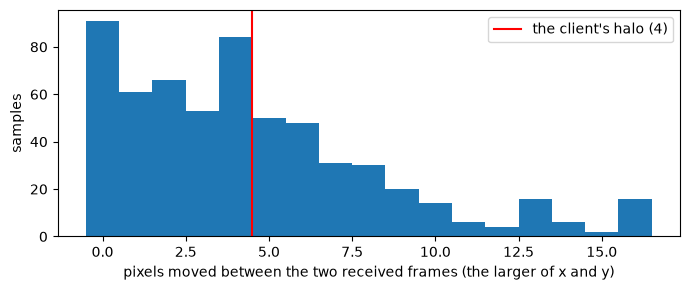

moved  0 px or less: 15.2% of 598 changed page and photo samples
moved  4 px or less: 59.4% of 598 changed page and photo samples
moved  8 px or less: 86.0% of 598 changed page and photo samples
moved 15 px or less: 97.3% of 598 changed page and photo samples


In [5]:
"""How far scrolled and panned content moves in a frame."""

scrolled = masks["changed"] & (masks.get("page", False) | masks.get("photo", False))
chosen = np.flatnonzero(scrolled)
finder = models.Shift(radius=HALO, block=None, fraction=FRACTION).to(DEVICE)
offsets = []
with torch.no_grad():
    for first in range(0, len(chosen), 256):
        batch = training.to_tensor(inputs[chosen[first:first + 256]])
        offsets += [finder.offsets[i] for i in finder.offsets_of(*batch.unbind(1)).flatten().tolist()]
reach = np.array([max(abs(dy), abs(dx)) for dy, dx in offsets])

fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(reach, bins=np.arange(HALO + 2) - 0.5)
ax.axvline(webexport.TILE_HALO + 0.5, color="red", label=f"the client's halo ({webexport.TILE_HALO})")
ax.set_xlabel("pixels moved between the two received frames (the larger of x and y)")
ax.set_ylabel("samples")
ax.legend()
fig.tight_layout()
plt.show()
for limit in (0, webexport.TILE_HALO, 8, HALO - 1):
    print(f"moved {limit:2} px or less: {(reach <= limit).mean():5.1%} of {len(reach)} changed page and photo samples")

## What they look like

One changed sample of each kind, the core and its halo (the red box is what is scored).
Look at the edges: linear draws a moved edge twice, the shift methods either land it or
smear it, and nothing gets a menu that was not there yet.

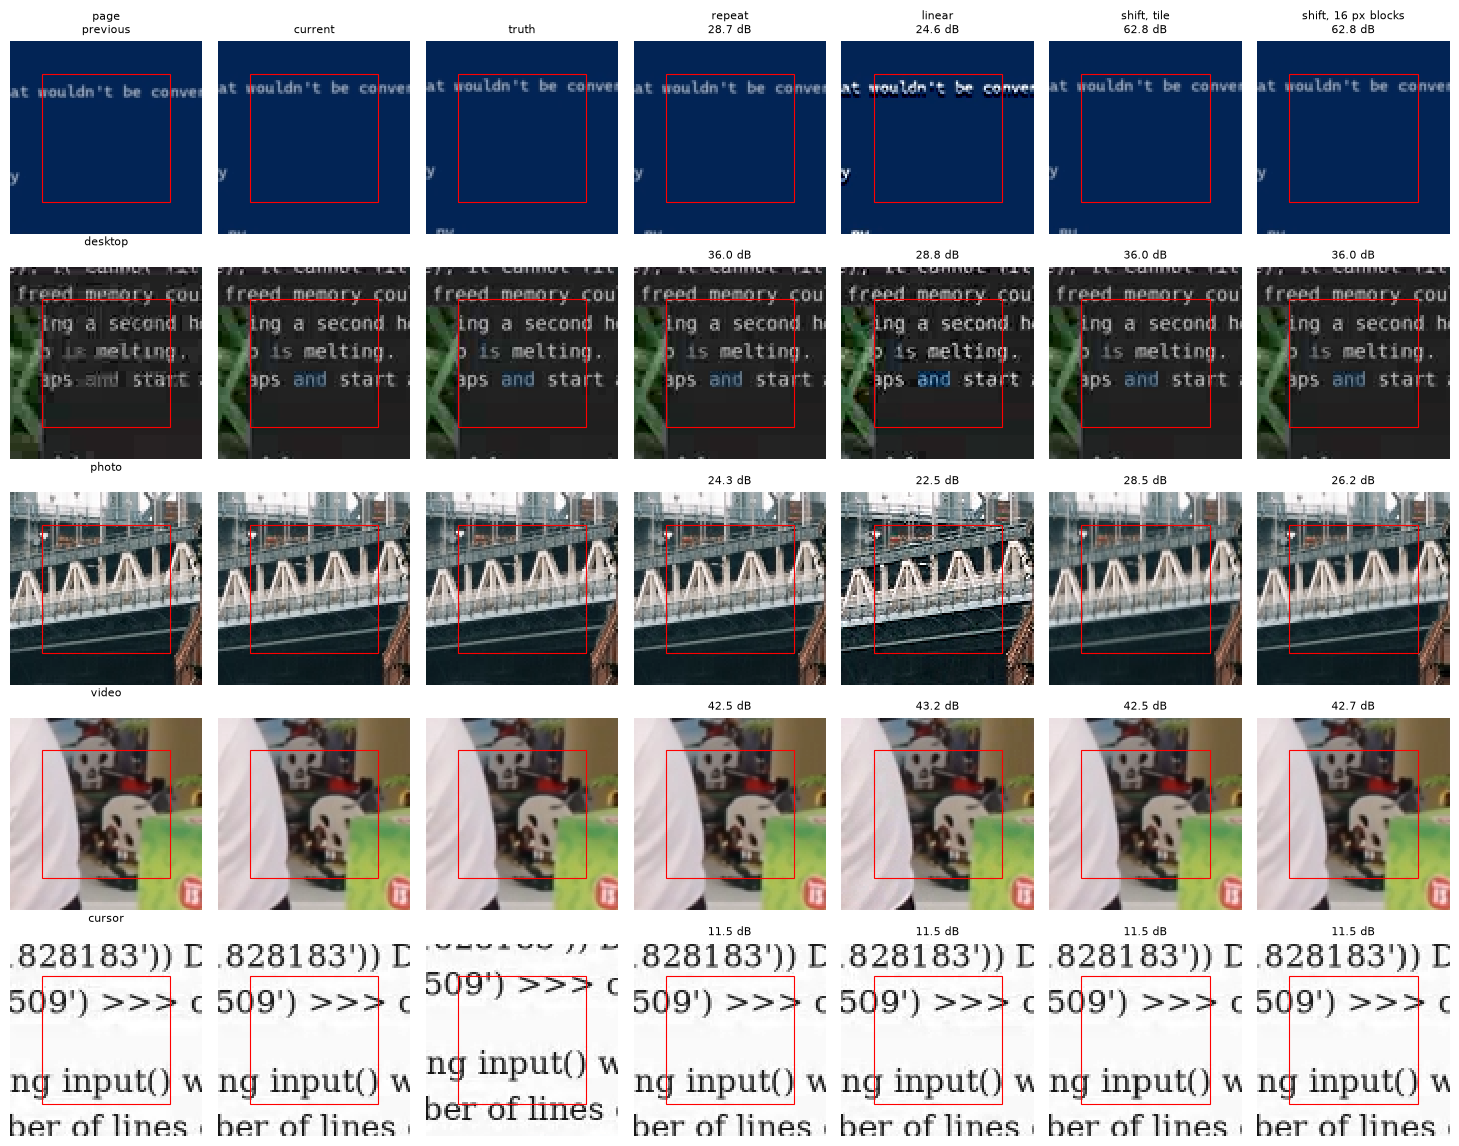

In [6]:
"""One changed sample of each kind through every method."""

show = ["repeat", "linear", "shift, tile", "shift, 16 px blocks"]
pick_rng = np.random.default_rng(SEED)
picks = [(kind, int(pick_rng.choice(np.flatnonzero(masks[f"{kind}, changed"]))))
         for kind in KINDS if masks[f"{kind}, changed"].any()]

columns = ["previous", "current", "truth", *show]
fig, axes = plt.subplots(len(picks), len(columns), figsize=(2.1 * len(columns), 2.3 * len(picks)), squeeze=False)
for row, (kind, index) in enumerate(picks):
    sample = training.to_tensor(inputs[index:index + 1])
    truth = training.to_tensor(targets[index:index + 1])
    pictures = {"previous": sample[:, 0], "current": sample[:, 1], "truth": truth}
    with torch.no_grad():
        for name in show:
            pictures[name] = METHODS[name].to(DEVICE)(sample[:, 0], sample[:, 1]).clamp(0, 1)
    for column, name in enumerate(columns):
        ax = axes[row][column]
        ax.imshow(pictures[name][0].permute(1, 2, 0).cpu().numpy(), interpolation="nearest")
        ax.add_patch(plt.Rectangle((HALO - 0.5, HALO - 0.5), manifest["core"], manifest["core"],
                                   fill=False, color="red", lw=0.8))
        title = name if row == 0 else ""
        if name in show:
            score = metrics.wpsnr(runs.trim(pictures[name], HALO), runs.trim(truth, HALO))
            title = f"{title}\n{score:.1f} dB" if title else f"{score:.1f} dB"
        if column == 0:
            title = f"{kind}\n{title}"
        ax.set_title(title, fontsize=8)
        ax.axis("off")
fig.tight_layout()
plt.show()

## Speed

Each method in torch on this computer's GPU, one stream frame at a time - the stream is
640x360 to 1920x1080 depending on what the client asked for. The tile method on a whole
frame finds one offset for all of it, which is not what it would do per tile; it is timed
only to show what the search costs. At a radius of 16 the search is 1089 offsets, each a few
small torch calls, so its time here is mostly launching them and hardly grows with the
frame: it says the search is not free, not what a fused kernel would cost.

In [7]:
"""torch, one frame at a time."""

speed_ms = {}
for width, height in BENCH_SIZES:
    previous, current = torch.rand(2, 1, 3, height, width, device=DEVICE)
    with torch.no_grad():
        speed_ms[width, height] = {name: speed.time_ms(lambda m=method: m(previous, current), seconds=0.3)
                                   for name, method in METHODS.items()}

print(f"{'frame':>11}" + "".join(f"{name.replace('shift, ', ''):>16}" for name in METHODS))
for (width, height), row in speed_ms.items():
    print(f"{f'{width}x{height}':>11}" + "".join(f"{row[name]:16.2f}" for name in METHODS))
print("ms per frame")

      frame          repeat          linear       half step            tile    16 px blocks     8 px blocks
    640x360            0.00            0.04            0.03           48.78           68.68           48.64
    960x540            0.00            0.08            0.08           55.45           93.76           45.87
   1280x720            0.00            0.14            0.14           55.03          102.74           45.21
  1920x1080            0.00            0.30            0.30           75.83          135.38           73.87
ms per frame


## The bar to beat

In [8]:
changed = {name: scores["changed"] for name, scores in results.items()}
best = max(changed, key=lambda name: changed[name]["ssim"])
print(f"quality: {best} at {changed[best]['ssim']:.4f} SSIM-Y, {changed[best]['wpsnr']:.2f} dB on the "
      f"{masks['changed'].sum()} changed samples (repeat {changed['repeat']['ssim']:.4f}, "
      f"{changed['repeat']['wpsnr']:.2f} dB; linear {changed['linear']['ssim']:.4f}, {changed['linear']['wpsnr']:.2f} dB)")
print(f"speed:   at 960x540, repeat costs {speed_ms[960, 540]['repeat']:.2f} ms, linear "
      f"{speed_ms[960, 540]['linear']:.2f} ms and {best} {speed_ms[960, 540][best]:.2f} ms (torch)")

quality: shift, tile at 0.8675 SSIM-Y, 35.80 dB on the 749 changed samples (repeat 0.7040, 25.69 dB; linear 0.6326, 21.94 dB)
speed:   at 960x540, repeat costs 0.00 ms, linear 0.08 ms and shift, tile 55.45 ms (torch)


## Export to ONNX for the client

The client runs `extrapolate.onnx` on 328x188 tiles (a 320x180 step and a halo of 4) with
two inputs, `previous` and `current`. Repeat and the two blends are a few elementwise
operators, so they export as they are, and replacing the mock is copying one over it. The
shift methods do not: their search is (2r+1)^2 shifted copies of the picture and a
comparison each, which a learned model would have to find another way.

In [9]:
"""Export repeat, linear and half step at the client's tile, and time them on the desktop CPU."""

EXPORTABLE = {"repeat": "static repeat", "linear": "static linear (the mock)", "half step": "static half step"}

step_h, step_w = webexport.TILE_STEP
for name, label in EXPORTABLE.items():
    module = METHODS[name].cpu()
    filename = f"extrapolate_static_{name.replace(' ', '_')}_tile{step_w}x{step_h}.onnx"
    info = webexport.export(module, filename, webexport.TILE_INPUT, label=label)
    example = np.random.rand(2, 1, 3, *webexport.TILE_INPUT).astype(np.float32)
    webexport.check_graph(info["path"], module, *example)
    ms = webexport.time_graph(info["path"], webexport.TILE_INPUT)
    webexport.annotate(info, cpu_ms=round(ms, 3))
    print(webexport.summary_line(info, ms))

print(f"\nwritten to {webexport.MODELS_DIR}")

extrapolate_static_repeat_tile320x180.onnx              0.3 KB    0.02 ms   Identityx1


extrapolate_static_linear_tile320x180.onnx              0.7 KB    0.03 ms   Addx1, Clipx1, Constantx3, Mulx1, Subx1   OUTSIDE BUDGET: Clip, Mul, Sub


extrapolate_static_half_step_tile320x180.onnx           0.7 KB    0.03 ms   Addx1, Clipx1, Constantx3, Mulx1, Subx1   OUTSIDE BUDGET: Clip, Mul, Sub

written to /home/henrik/desktop-streamer-ai/dist/frame_gen_extra
